# 評価指標
正解率だけでは見えない、モデルの間違い方の特徴を調べます。混同行列から、適合率・再現率・F1 スコアを求め、確率の予測の良さを表す ROC 曲線と AUC も学びます。

## 学習目標
- 混同行列を作り、4つのマス(TP・FP・FN・TN)の意味を説明できる
- 適合率・再現率・F1 スコアを求め、目的に合った指標を選べる
- ROC 曲線を描き、AUC の意味を説明できる

## 混同行列

予測と正解の組み合わせを数えた表を **混同行列** といいます。scikit-learn の `confusion_matrix` は、行が正解、列が予測の順に並んだ表を返します。

|  | 予測:死亡(0) | 予測:生存(1) |
|---|---|---|
| **正解:死亡(0)** | TN(正しく死亡と予測) | FP(死亡なのに生存と予測) |
| **正解:生存(1)** | FN(生存なのに死亡と予測) | TP(正しく生存と予測) |

前の単元の、深さ 5 のランダムフォレストで混同行列を作ります。

In [1]:
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix
from sklearn.model_selection import train_test_split

# 特徴量の表を読み込み、学習用と検証用に分ける(これまでと同じ分け方)
df = pd.read_csv("train_prepared.csv")
X = df.drop(columns=["PassengerId", "Survived"])
y = df["Survived"]
X_train, X_valid, y_train, y_valid = train_test_split(X, y, test_size=0.25, random_state=0, stratify=y)

# 深さ 5 のランダムフォレストを学習させ、検証用のデータを予測する
forest = RandomForestClassifier(n_estimators=100, max_depth=5, random_state=0).fit(X_train, y_train)
pred = forest.predict(X_valid)

# 混同行列(行 = 正解、列 = 予測)
print(confusion_matrix(y_valid, pred))

[[122  18]
 [ 24  59]]


- TN = 122:死亡した 140 人のうち、122 人を正しく死亡と予測
- FP = 18:死亡した人のうち 18 人を、生存と予測(間違い)
- FN = 24:生存した 83 人のうち、24 人を死亡と予測(間違い)
- TP = 59:生存した人のうち 59 人を、正しく生存と予測

正解率は (122 + 59) ÷ 223 = 81.2% です。

## 適合率・再現率・F1 スコア

| 指標 | 計算 | 意味 |
|---|---|---|
| **適合率**(precision) | TP ÷ (TP + FP) | 「生存」と予測した人のうち、実際に生存した割合。予測の **確かさ** |
| **再現率**(recall) | TP ÷ (TP + FN) | 実際に生存した人のうち、「生存」と予測できた割合。**見逃しの少なさ** |
| **F1 スコア** | 2 × 適合率 × 再現率 ÷ (適合率 + 再現率) | 適合率と再現率のバランス(調和平均) |

In [2]:
from sklearn.metrics import f1_score, precision_score, recall_score

# 適合率・再現率・F1 スコアを求める(正解、予測の順に渡す)
print("適合率:", round(precision_score(y_valid, pred), 3))
print("再現率:", round(recall_score(y_valid, pred), 3))
print("F1    :", round(f1_score(y_valid, pred), 3))

適合率: 0.766
再現率: 0.711
F1    : 0.738


適合率は 59 ÷ (59 + 18) = 76.6%、再現率は 59 ÷ (59 + 24) = 71.1% です。このモデルは、生存した人の約 3 割を見逃しています。

**どの指標を重視するか** は目的によって決まります。例えば病気の検査のように **見逃しを減らしたい** ときは再現率、迷惑メールの判定のように **誤って判定すると困る** ときは適合率を重視します。単元2で確かめたように、しきい値を下げると再現率が上がり、上げると適合率が上がる傾向があります。

## ROC 曲線と AUC

しきい値を 0 から 1 まで変えながら、「死亡した人を誤って生存と予測した割合(偽陽性率)」を横軸に、「生存した人を生存と予測できた割合(再現率)」を縦軸にとって描いた曲線を **ROC 曲線** といいます。曲線の下の面積が **AUC** で、0.5(でたらめな予測)から 1(完璧な予測)の値をとります。AUC はしきい値によらない、**確率の予測の良さ** を表す指標です。

AUC: 0.802


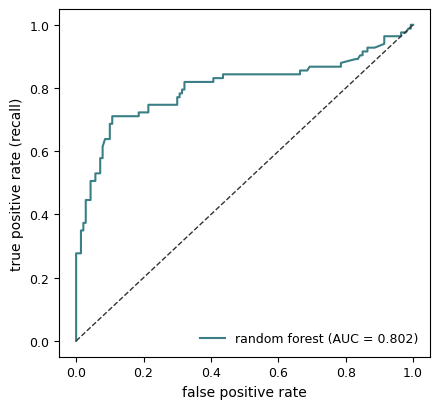

In [3]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score, roc_curve

# 生存の確率を求める
proba = forest.predict_proba(X_valid)[:, 1]

# ROC 曲線の点(偽陽性率 fpr、再現率 tpr)と AUC を求める
fpr, tpr, thresholds = roc_curve(y_valid, proba)
auc = roc_auc_score(y_valid, proba)
print("AUC:", round(auc, 3))

# ROC 曲線を描く。点線はでたらめな予測(AUC = 0.5)の線
fig, ax = plt.subplots(figsize=(4.5, 4.2))
ax.plot(fpr, tpr, label=f"random forest (AUC = {auc:.3f})")
ax.plot([0, 1], [0, 1], color="#333333", linestyle="--", linewidth=1)
ax.set_xlabel("false positive rate")
ax.set_ylabel("true positive rate (recall)")
ax.legend(loc="lower right")
fig.tight_layout()
plt.show()

AUC は 0.802 です。曲線が左上に近いほど、少ない誤りで多くの生存者を見つけられる良いモデルです。

## 演習

単元2の標準化したロジスティック回帰について、検証用のデータで **混同行列** を表示し、続けて **適合率・再現率・F1 スコア** を、この順に小数第3位まで表示してください。

In [ ]:
# @starter
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, f1_score, precision_score, recall_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# 特徴量の表を読み込み、学習用と検証用に分ける
df = pd.read_csv("train_prepared.csv")
X = df.drop(columns=["PassengerId", "Survived"])
y = df["Survived"]
X_train, X_valid, y_train, y_valid = train_test_split(X, y, test_size=0.25, random_state=0, stratify=y)

# 標準化したロジスティック回帰を学習させ、検証用のデータを予測する
scaler = StandardScaler().fit(X_train)
model = LogisticRegression(max_iter=1000).fit(scaler.transform(X_train), y_train)
pred = model.predict(scaler.transform(X_valid))

# 混同行列を表示する(____ に、正解と予測を渡す)
print(confusion_matrix(____, ____))

# 適合率・再現率・F1 スコアを表示する(____ に、それぞれを求める関数の名前を入れる)
print(round(____(y_valid, pred), 3))
print(round(____(y_valid, pred), 3))
print(round(____(y_valid, pred), 3))

In [4]:
# @solution
# @title: ロジスティック回帰の評価指標
# @hint: confusion_matrix(y_valid, pred) のように、正解・予測の順に渡します。適合率は precision_score、再現率は recall_score、F1 スコアは f1_score です。
# @explanation: ロジスティック回帰は TP = 60、FN = 23 で、再現率は 72.3% とランダムフォレスト(71.1%)より少し高く、適合率は 75.0% と少し低くなっています。F1 スコアは 0.736 で、ランダムフォレスト(0.738)とほぼ同じです。正解率だけでなく、間違い方の違いも比べられます。
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, f1_score, precision_score, recall_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# 特徴量の表を読み込み、学習用と検証用に分ける
df = pd.read_csv("train_prepared.csv")
X = df.drop(columns=["PassengerId", "Survived"])
y = df["Survived"]
X_train, X_valid, y_train, y_valid = train_test_split(X, y, test_size=0.25, random_state=0, stratify=y)

# 標準化したロジスティック回帰を学習させ、検証用のデータを予測する
scaler = StandardScaler().fit(X_train)
model = LogisticRegression(max_iter=1000).fit(scaler.transform(X_train), y_train)
pred = model.predict(scaler.transform(X_valid))

# 混同行列を表示する(正解、予測の順に渡す)
print(confusion_matrix(y_valid, pred))

# 適合率・再現率・F1 スコアを表示する
print(round(precision_score(y_valid, pred), 3))
print(round(recall_score(y_valid, pred), 3))
print(round(f1_score(y_valid, pred), 3))

[[120  20]
 [ 23  60]]
0.75
0.723
0.736


単元2の標準化したロジスティック回帰について、検証用のデータでの **AUC** を小数第3位まで表示してください。

In [ ]:
# @starter
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# 特徴量の表を読み込み、学習用と検証用に分ける
df = pd.read_csv("train_prepared.csv")
X = df.drop(columns=["PassengerId", "Survived"])
y = df["Survived"]
X_train, X_valid, y_train, y_valid = train_test_split(X, y, test_size=0.25, random_state=0, stratify=y)

# 標準化したロジスティック回帰を学習させる
scaler = StandardScaler().fit(X_train)
model = LogisticRegression(max_iter=1000).fit(scaler.transform(X_train), y_train)

# AUC は 0 / 1 の予測ではなく、生存の「確率」から求める(____ に、確率を求める式を書く)
proba = ____
print(round(roc_auc_score(y_valid, proba), 3))

In [5]:
# @solution
# @title: ロジスティック回帰の AUC
# @hint: 生存の確率は model.predict_proba(scaler.transform(X_valid))[:, 1] で求めます。検証用のデータも、学習用と同じ scaler で変換してから渡します。
# @explanation: ロジスティック回帰の AUC は 0.837 で、ランダムフォレスト(0.802)より高くなりました。正解率はランダムフォレストの方が少し高かったものの、確率の予測の順番(生存しやすい人ほど高い確率になっているか)は、ロジスティック回帰の方が良いことがわかります。
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# 特徴量の表を読み込み、学習用と検証用に分ける
df = pd.read_csv("train_prepared.csv")
X = df.drop(columns=["PassengerId", "Survived"])
y = df["Survived"]
X_train, X_valid, y_train, y_valid = train_test_split(X, y, test_size=0.25, random_state=0, stratify=y)

# 標準化したロジスティック回帰を学習させる
scaler = StandardScaler().fit(X_train)
model = LogisticRegression(max_iter=1000).fit(scaler.transform(X_train), y_train)

# 検証用のデータを同じ scaler で変換し、生存の確率([:, 1])を求めてから AUC を計算する
proba = model.predict_proba(scaler.transform(X_valid))[:, 1]
print(round(roc_auc_score(y_valid, proba), 3))

0.837


<!-- @question
type: choice
answer: 再現率
title: 目的に合った評価指標
hint: 「助けが必要な人を見逃したくない」とき、どの間違い(FP・FN)を減らしたいかを考えます。
explanation: 救助が必要な人(正解が 1)を見逃す間違いは FN です。FN を減らす、つまり実際に救助が必要な人のうち、正しく見つけられた割合を高めたいので、再現率(TP ÷ (TP + FN))を重視します。
-->
災害時に「救助が必要な人」を予測するモデルを作る。救助が必要な人を見逃すことを最も避けたい。このとき最も重視すべき評価指標を選べ。

- 正解率
- 適合率
- 再現率
- 特徴量の重要度

## まとめ

- 混同行列(TN・FP・FN・TP)で、モデルの間違い方を確かめる。
- 適合率は予測の確かさ、再現率は見逃しの少なさ、F1 スコアはその両方のバランス。目的に合わせて重視する指標を選ぶ。
- ROC 曲線と AUC は、しきい値によらない確率の予測の良さを表す。正解率が高いモデルが、AUC も高いとは限らない。